In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np

In [37]:
def plot_2d_vectors(
    vectors,
    origins=None,
    labels=None,
    colors=None,
    scale=1.0,
    title="2D Force Vectors",
    center_origin=True,
):
    """Plots a collection of 2D vectors with arrows, centered at (0, 0) by default.

    Parameters:
    - vectors: list or (N, 2) array of [vx, vy] components
    - origins: list or (N, 2) array of [x, y] tail positions (defaults to [0,
    0])
    - labels: list of strings for the legend
    - colors: list of color strings
    - scale: multiplier to resize vector lengths visually (default 1.0 = true
    size)
    - center_origin: if True, keeps (0, 0) at the exact center of the plot
    """
    vectors = np.atleast_2d(np.asarray(vectors, dtype=float))
    n = len(vectors)

    if origins is None:
        origins = np.zeros_like(vectors)
    else:
        origins = np.atleast_2d(np.asarray(origins, dtype=float))
        if len(origins) == 1 and n > 1:
            origins = np.repeat(origins, n, axis=0)

    if colors is None:
        colors = plt.cm.tab10(np.linspace(0, 1, max(n, 10)))[:n]

    fig, ax = plt.subplots(figsize=(6, 6))

    # Plot each vector
    for i in range(n):
        vec = vectors[i] * scale
        orig = origins[i]
        lbl = labels[i] if labels and i < len(labels) else f"Vector {i+1}"

        ax.quiver(
            orig[0],
            orig[1],
            vec[0],
            vec[1],
            angles="xy",
            scale_units="xy",
            scale=1,
            color=colors[i],
            width=0.008,
            label=lbl,
        )

    # Calculate bounding points
    tips = origins + vectors * scale
    all_pts = np.vstack([origins, tips, [[0, 0]]])

    if center_origin:
        # Find the furthest coordinate from (0, 0) across both X and Y
        max_abs = np.max(np.abs(all_pts)) or 1.0
        limit = max_abs * 1.2  # Add 20% padding
        ax.set_xlim(-limit, limit)
        ax.set_ylim(-limit * 0.1, limit)
    else:
        min_xy = all_pts.min(axis=0)
        max_xy = all_pts.max(axis=0)
        span = np.max(max_xy - min_xy) or 1.0
        pad = span * 0.2
        ax.set_xlim(min_xy[0] - pad, max_xy[0] + pad)
        ax.set_ylim(min_xy[1] - pad, max_xy[1] + pad)

    # Draw central axes lines and formatting
    # ax.axvline(0, c="black")
    ax.axhline(0, c="green", lw=2.0)
    ax.set_aspect("equal")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_title(title)
    if labels:
        ax.legend(loc="upper left")

    plt.tight_layout()
    plt.show()
    return fig, ax

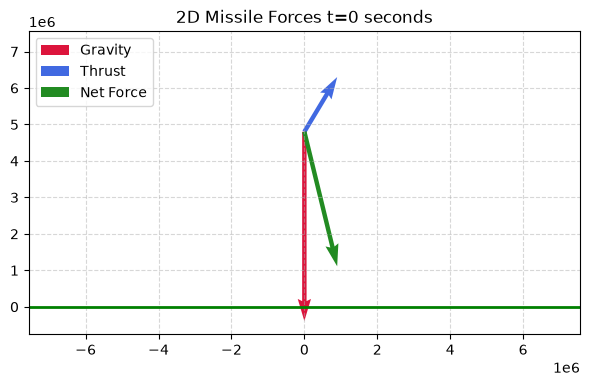

(<Figure size 600x600 with 1 Axes>,
 <Axes: title={'center': '2D Missile Forces t=0 seconds'}>)

In [45]:
G = 6.67430e-11
M_earth = 5.972e24
m_missile = 1000.0

pos_missile = np.array([0, 4.8e6])
r_mag = np.linalg.norm(pos_missile)

# Force vectors (in Newtons)
f_gravity = -G * M_earth * m_missile * pos_missile / (r_mag**3)
f_thrust = np.array([3000.0, 5000.0])
f_net = f_gravity + f_thrust

# Scale Newtons (~10^3) to match spatial coordinates (~10^6 meters)
plot_2d_vectors(
    vectors=[f_gravity, f_thrust, f_net],
    origins=pos_missile,
    labels=["Gravity", "Thrust", "Net Force"],
    colors=["crimson", "royalblue", "forestgreen"],
    scale=300,
    title="2D Missile Forces t=0 seconds",
)